# Scientific Interest in AMR

This notebook extracts the minimal normalization workflow from `5_normalisation.ipynb` and treats `resid_log_bg` as **scientific interest** (`SI`). It then fits a Gaussian process to the SI trajectory of a selected pathogen-antibiotic pair and compares the prediction against observed SI.

In [78]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

from amr.normalisation import BackgroundNormaliseConfig, normalise_by_background

warnings.filterwarnings("ignore", category=ConvergenceWarning)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load the data needed to compute SI

The only inputs required from the normalization notebook are:

- `pmids_results_positive.parquet`
- `pathogen_tiab_counts.parquet`
- `antibiotic_tiab_counts.parquet`

If `amr_df_normalised.parquet` already exists, the notebook reuses it. Otherwise it recomputes it and saves a cache.

In [79]:
def load_scientific_interest_df(*, alpha: float = 1.0, use_cached: bool = True, save_cache: bool = True) -> pd.DataFrame:
    cache_path = "amr_df_normalised.parquet"

    if use_cached and os.path.exists(cache_path):
        si_df = pd.read_parquet(cache_path)
    else:
        amr_df = pd.read_parquet("pmids_results_positive.parquet")
        pa_counts_df = pd.read_parquet("pathogen_tiab_counts.parquet")
        ab_counts_df = pd.read_parquet("antibiotic_tiab_counts.parquet")

        si_df = normalise_by_background(
            amr_df,
            pathogen_year_df=pa_counts_df,
            antibiotic_year_df=ab_counts_df,
            cfg=BackgroundNormaliseConfig(alpha=alpha),
        )
        if save_cache:
            si_df.to_parquet(cache_path, index=False)

    si_df = si_df.copy()
    si_df["start_year"] = pd.to_datetime(si_df["start_date"]).dt.year.astype(int)
    si_df["end_year"] = pd.to_datetime(si_df["end_date"]).dt.year.astype(int)
    si_df["mid_year"] = (si_df["start_year"] + si_df["end_year"]) / 2.0
    si_df["SI"] = pd.to_numeric(si_df["resid_log_bg"], errors="coerce")
    si_df = si_df.dropna(subset=["SI"])
    return si_df


si_df = load_scientific_interest_df()
si_df[["pathogen", "antibiotic", "start_year", "end_year", "count", "expected_bg", "resid_log_bg", "SI"]].head()

,pathogen,antibiotic,start_year,end_year,count,expected_bg,resid_log_bg,SI
0,Abiotrophia defectiva,Cefepime,2015,2019,1,1.000000,5.000000e-10,5.000000e-10
1,Abiotrophia defectiva,Cefotaxime,2015,2019,1,1.000000,5.000000e-10,5.000000e-10
2,Abiotrophia defectiva,Ceftriaxone,2010,2014,1,1.000000,5.000000e-10,5.000000e-10
3,Abiotrophia defectiva,Ciprofloxacin,2010,2014,1,1.000000,5.000000e-10,5.000000e-10
4,Abiotrophia defectiva,Clindamycin,2000,2004,1,1.055633,-2.743656e-02,-2.743656e-02


In [80]:
def get_pair_si_series(si_df: pd.DataFrame, pathogen: str, antibiotic: str) -> pd.DataFrame:
    pair_df = (
        si_df.loc[
            (si_df["pathogen"] == pathogen) &
            (si_df["antibiotic"] == antibiotic),
            [
                "pathogen",
                "antibiotic",
                "start_date",
                "end_date",
                "start_year",
                "end_year",
                "mid_year",
                "count",
                "expected_bg",
                "bg_pathogen_n",
                "bg_antibiotic_n",
                "SI",
            ],
        ]
        .sort_values(["end_year", "start_year"])
        .reset_index(drop=True)
    )

    if pair_df.empty:
        raise ValueError(f"No SI data found for pathogen={pathogen!r}, antibiotic={antibiotic!r}.")

    pair_df = (
        pair_df.groupby(["pathogen", "antibiotic", "start_year", "end_year", "mid_year"], as_index=False)
        .agg(
            {
                "count": "sum",
                "expected_bg": "sum",
                "bg_pathogen_n": "max",
                "bg_antibiotic_n": "max",
                "SI": "mean",
            }
        )
        .sort_values("end_year")
        .reset_index(drop=True)
    )
    return pair_df


def fit_predict_si_gp(
    si_df: pd.DataFrame,
    pathogen: str,
    antibiotic: str,
    fit_start_year: int,
    fit_end_year: int,
    num_additional_years: int = 5,
    *,
    min_train_points: int = 3,
    n_restarts_optimizer: int = 8,
    random_state: int = 0,
) -> dict:
    if fit_end_year < fit_start_year:
        raise ValueError("fit_end_year must be >= fit_start_year.")
    if num_additional_years < 0:
        raise ValueError("num_additional_years must be >= 0.")

    pair_df = get_pair_si_series(si_df, pathogen, antibiotic)
    latest_available_year = int(pair_df["end_year"].max())

    train_df = pair_df.loc[
        pair_df["end_year"].between(int(fit_start_year), int(fit_end_year))
    ].copy()

    if train_df["end_year"].nunique() < min_train_points:
        raise ValueError(
            f"Need at least {min_train_points} observed intervals between {fit_start_year} and {fit_end_year}; "
            f"found {train_df['end_year'].nunique()}."
        )

    x_train = train_df[["end_year"]].to_numpy(dtype=float)
    y_train = train_df["SI"].to_numpy(dtype=float)

    y_scale = float(np.nanstd(y_train))
    signal_scale = max(y_scale, 1e-2)
    kernel = (
        ConstantKernel(signal_scale, (1e-3, 1e3))
        * RBF(length_scale=10.0, length_scale_bounds=(1.0, 100.0))
        + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-6, 10.0))
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=n_restarts_optimizer,
        random_state=random_state,
    )
    gp.fit(x_train, y_train)

    prediction_start_year = int(fit_end_year)
    prediction_end_year = latest_available_year + int(num_additional_years)
    gp_plot_start_year = int(pair_df["end_year"].min())
    x_pred = np.arange(gp_plot_start_year, prediction_end_year + 1, dtype=float).reshape(-1, 1)
    pred_mean, pred_std = gp.predict(x_pred, return_std=True)

    pred_df = pd.DataFrame(
        {
            "year": x_pred.ravel().astype(int),
            "predicted_SI": pred_mean,
            "predicted_std": pred_std,
        }
    )
    pred_df["lower_1std"] = pred_df["predicted_SI"] - pred_df["predicted_std"]
    pred_df["upper_1std"] = pred_df["predicted_SI"] + pred_df["predicted_std"]

    observed_future_df = pair_df.loc[pair_df["end_year"] >= prediction_start_year, ["end_year", "SI"]].copy()
    observed_future_df = observed_future_df.rename(columns={"end_year": "year", "SI": "observed_SI"})

    comparison_df = observed_future_df.merge(pred_df, on="year", how="left")
    comparison_df["prediction_error"] = comparison_df["observed_SI"] - comparison_df["predicted_SI"]
    comparison_df["abs_error"] = comparison_df["prediction_error"].abs()
    comparison_df["within_1std"] = (
        (comparison_df["observed_SI"] >= comparison_df["lower_1std"])
        & (comparison_df["observed_SI"] <= comparison_df["upper_1std"])
    )

    return {
        "pathogen": pathogen,
        "antibiotic": antibiotic,
        "fit_start_year": int(fit_start_year),
        "fit_end_year": int(fit_end_year),
        "latest_available_year": latest_available_year,
        "num_additional_years": int(num_additional_years),
        "gp_plot_start_year": gp_plot_start_year,
        "pair_df": pair_df,
        "train_df": train_df,
        "pred_df": pred_df,
        "comparison_df": comparison_df,
        "gp": gp,
    }


def forecast_si_for_all_pairs(
    si_df: pd.DataFrame,
    fit_start_year: int = 1970,
    fit_end_year: int = 2015,
    num_additional_years: int = 5,
    *,
    current_year: int | None = None,
    min_train_points: int = 3,
    n_restarts_optimizer: int = 8,
    random_state: int = 0,
    save_path: str | None = None,
) -> pd.DataFrame:
    if current_year is None:
        current_year = int(pd.Timestamp.today().year)
    target_year = int(current_year) + int(num_additional_years)

    pair_index_df = (
        si_df[["pathogen", "antibiotic"]]
        .drop_duplicates()
        .sort_values(["pathogen", "antibiotic"])
        .reset_index(drop=True)
    )

    rows = []
    for pair in pair_index_df.itertuples(index=False):
        pathogen = str(pair.pathogen)
        antibiotic = str(pair.antibiotic)
        try:
            result = fit_predict_si_gp(
                si_df=si_df,
                pathogen=pathogen,
                antibiotic=antibiotic,
                fit_start_year=fit_start_year,
                fit_end_year=fit_end_year,
                num_additional_years=max(num_additional_years, target_year - fit_end_year),
                min_train_points=min_train_points,
                n_restarts_optimizer=n_restarts_optimizer,
                random_state=random_state,
            )
            pred_mean, pred_std = result["gp"].predict(np.array([[target_year]], dtype=float), return_std=True)
            pair_df = result["pair_df"]
            train_df = result["train_df"]
            rows.append(
                {
                    "pathogen": pathogen,
                    "antibiotic": antibiotic,
                    "fit_start_year": int(fit_start_year),
                    "fit_end_year": int(fit_end_year),
                    "current_year": int(current_year),
                    "forecast_year": int(target_year),
                    "num_additional_years": int(num_additional_years),
                    "predicted_SI_mean": float(pred_mean[0]),
                    "predicted_SI_std": float(pred_std[0]),
                    "predicted_SI_lower_1std": float(pred_mean[0] - pred_std[0]),
                    "predicted_SI_upper_1std": float(pred_mean[0] + pred_std[0]),
                    "latest_available_year": int(result["latest_available_year"]),
                    "pair_first_year": int(pair_df["end_year"].min()),
                    "pair_last_year": int(pair_df["end_year"].max()),
                    "n_pair_intervals": int(pair_df["end_year"].nunique()),
                    "n_train_intervals": int(train_df["end_year"].nunique()),
                    "amr_pair_total_count": float(pair_df["count"].sum()),
                    "status": "ok",
                    "error": None,
                }
            )
        except Exception as exc:
            rows.append(
                {
                    "pathogen": pathogen,
                    "antibiotic": antibiotic,
                    "fit_start_year": int(fit_start_year),
                    "fit_end_year": int(fit_end_year),
                    "current_year": int(current_year),
                    "forecast_year": int(target_year),
                    "num_additional_years": int(num_additional_years),
                    "predicted_SI_mean": np.nan,
                    "predicted_SI_std": np.nan,
                    "predicted_SI_lower_1std": np.nan,
                    "predicted_SI_upper_1std": np.nan,
                    "latest_available_year": np.nan,
                    "pair_first_year": np.nan,
                    "pair_last_year": np.nan,
                    "n_pair_intervals": np.nan,
                    "n_train_intervals": np.nan,
                    "amr_pair_total_count": np.nan,
                    "status": "failed",
                    "error": str(exc),
                }
            )

    forecast_df = pd.DataFrame(rows).sort_values(
        ["status", "predicted_SI_mean", "amr_pair_total_count"],
        ascending=[True, False, False],
        na_position="last",
    ).reset_index(drop=True)

    if save_path is None:
        save_path = (
            f"si_pair_forecasts_fit_{int(fit_start_year)}_{int(fit_end_year)}"
            f"_target_{int(target_year)}.parquet"
        )
    forecast_df.to_parquet(save_path, index=False)
    return forecast_df


def plot_si_prediction(
    si_df: pd.DataFrame,
    pathogen: str,
    antibiotic: str,
    fit_start_year: int,
    fit_end_year: int,
    num_additional_years: int = 5,
    *,
    figsize: tuple[int, int] = (12, 6),
) -> dict:
    result = fit_predict_si_gp(
        si_df=si_df,
        pathogen=pathogen,
        antibiotic=antibiotic,
        fit_start_year=fit_start_year,
        fit_end_year=fit_end_year,
        num_additional_years=num_additional_years,
    )

    pair_df = result["pair_df"]
    train_df = result["train_df"]
    pred_df = result["pred_df"]
    comparison_df = result["comparison_df"]

    fig, ax = plt.subplots(figsize=figsize)
    ax2 = ax.twinx()

    count_plot_df = pair_df[["end_year", "count", "bg_pathogen_n", "bg_antibiotic_n"]].copy()
    count_plot_df["count_plot"] = np.clip(count_plot_df["count"].astype(float), 1.0, None)
    count_plot_df["bg_pathogen_plot"] = np.clip(count_plot_df["bg_pathogen_n"].astype(float), 1.0, None)
    count_plot_df["bg_antibiotic_plot"] = np.clip(count_plot_df["bg_antibiotic_n"].astype(float), 1.0, None)
    bar_width = 1.15
    ax2.bar(
        count_plot_df["end_year"] - bar_width,
        count_plot_df["count_plot"],
        width=bar_width,
        color="lightskyblue",
        alpha=0.4,
        label="Per-interval AMR count",
        zorder=0,
    )
    ax2.bar(
        count_plot_df["end_year"],
        count_plot_df["bg_pathogen_plot"],
        width=bar_width,
        color="tab:green",
        alpha=0.28,
        label="Pathogen background count",
        zorder=0,
    )
    ax2.bar(
        count_plot_df["end_year"] + bar_width,
        count_plot_df["bg_antibiotic_plot"],
        width=bar_width,
        color="tab:purple",
        alpha=0.22,
        label="Antibiotic background count",
        zorder=0,
    )
    ax2.set_yscale("log")
    ax2.set_ylabel("Publication counts (log scale)", color="tab:blue")
    ax2.tick_params(axis="y", labelcolor="tab:blue")

    observed_fit_df = pair_df.loc[pair_df["end_year"] <= int(fit_end_year)].copy()
    observed_future_df = pair_df.loc[pair_df["end_year"] > int(fit_end_year)].copy()
    if not observed_fit_df.empty and not observed_future_df.empty:
        observed_future_df = pd.concat(
            [observed_fit_df.tail(1), observed_future_df],
            ignore_index=True,
        )

    ax.plot(
        observed_fit_df["end_year"],
        observed_fit_df["SI"],
        color="navy",
        marker="o",
        markersize=7,
        markerfacecolor="white",
        markeredgecolor="navy",
        markeredgewidth=1.8,
        linewidth=2.8,
        linestyle="-",
        label="Observed SI (fit region)",
        zorder=3,
    )
    ax.plot(
        observed_future_df["end_year"],
        observed_future_df["SI"],
        color="navy",
        marker="o",
        markersize=7,
        markerfacecolor="white",
        markeredgecolor="navy",
        markeredgewidth=1.8,
        linewidth=2.8,
        linestyle="--",
        label="Observed SI (after fit window)",
        zorder=3,
    )
    fit_pred_df = pred_df.loc[pred_df["year"] <= int(fit_end_year)].copy()
    forecast_pred_df = pred_df.loc[pred_df["year"] >= int(fit_end_year)].copy()

    ax.plot(
        fit_pred_df["year"],
        fit_pred_df["predicted_SI"],
        color="tab:red",
        linewidth=2.2,
        linestyle="-",
        label="GP mean (fit region)",
        zorder=4,
    )
    ax.plot(
        forecast_pred_df["year"],
        forecast_pred_df["predicted_SI"],
        color="tab:red",
        linewidth=2.2,
        linestyle="--",
        label="GP mean (forecast region)",
        zorder=4,
    )
    ax.fill_between(
        pred_df["year"],
        pred_df["lower_1std"],
        pred_df["upper_1std"],
        color="tab:red",
        alpha=0.18,
        label="GP ±1 std",
        zorder=2,
    )

    ax.axvline(int(fit_end_year), color="tab:blue", linestyle="--", linewidth=1.2, alpha=0.8)
    ax.axvspan(int(result["gp_plot_start_year"]), int(fit_end_year), color="tab:blue", alpha=0.05, zorder=-1)
    ax.text(
        int(fit_end_year) + 0.2,
        ax.get_ylim()[1],
        f"fit end = {fit_end_year}",
        va="top",
        ha="left",
        fontsize=10,
        color="tab:blue",
    )

    ax.set_title(f"Scientific Interest (SI) GP fit: {pathogen} vs {antibiotic}")
    ax.set_xlabel("Interval end year")
    ax.set_ylabel("SI = resid_log_bg")
    ax.grid(alpha=0.25)
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False,
    )
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

    return result

## Example

The function input is exactly:

- `pathogen`
- `antibiotic`
- `fit_start_year`
- `fit_end_year`
- `num_additional_years`

The GP is fitted on observed SI intervals whose `end_year` lies between `fit_start_year` and `fit_end_year`. Prediction starts at `fit_end_year` and runs to the latest available observed interval year plus `num_additional_years`.

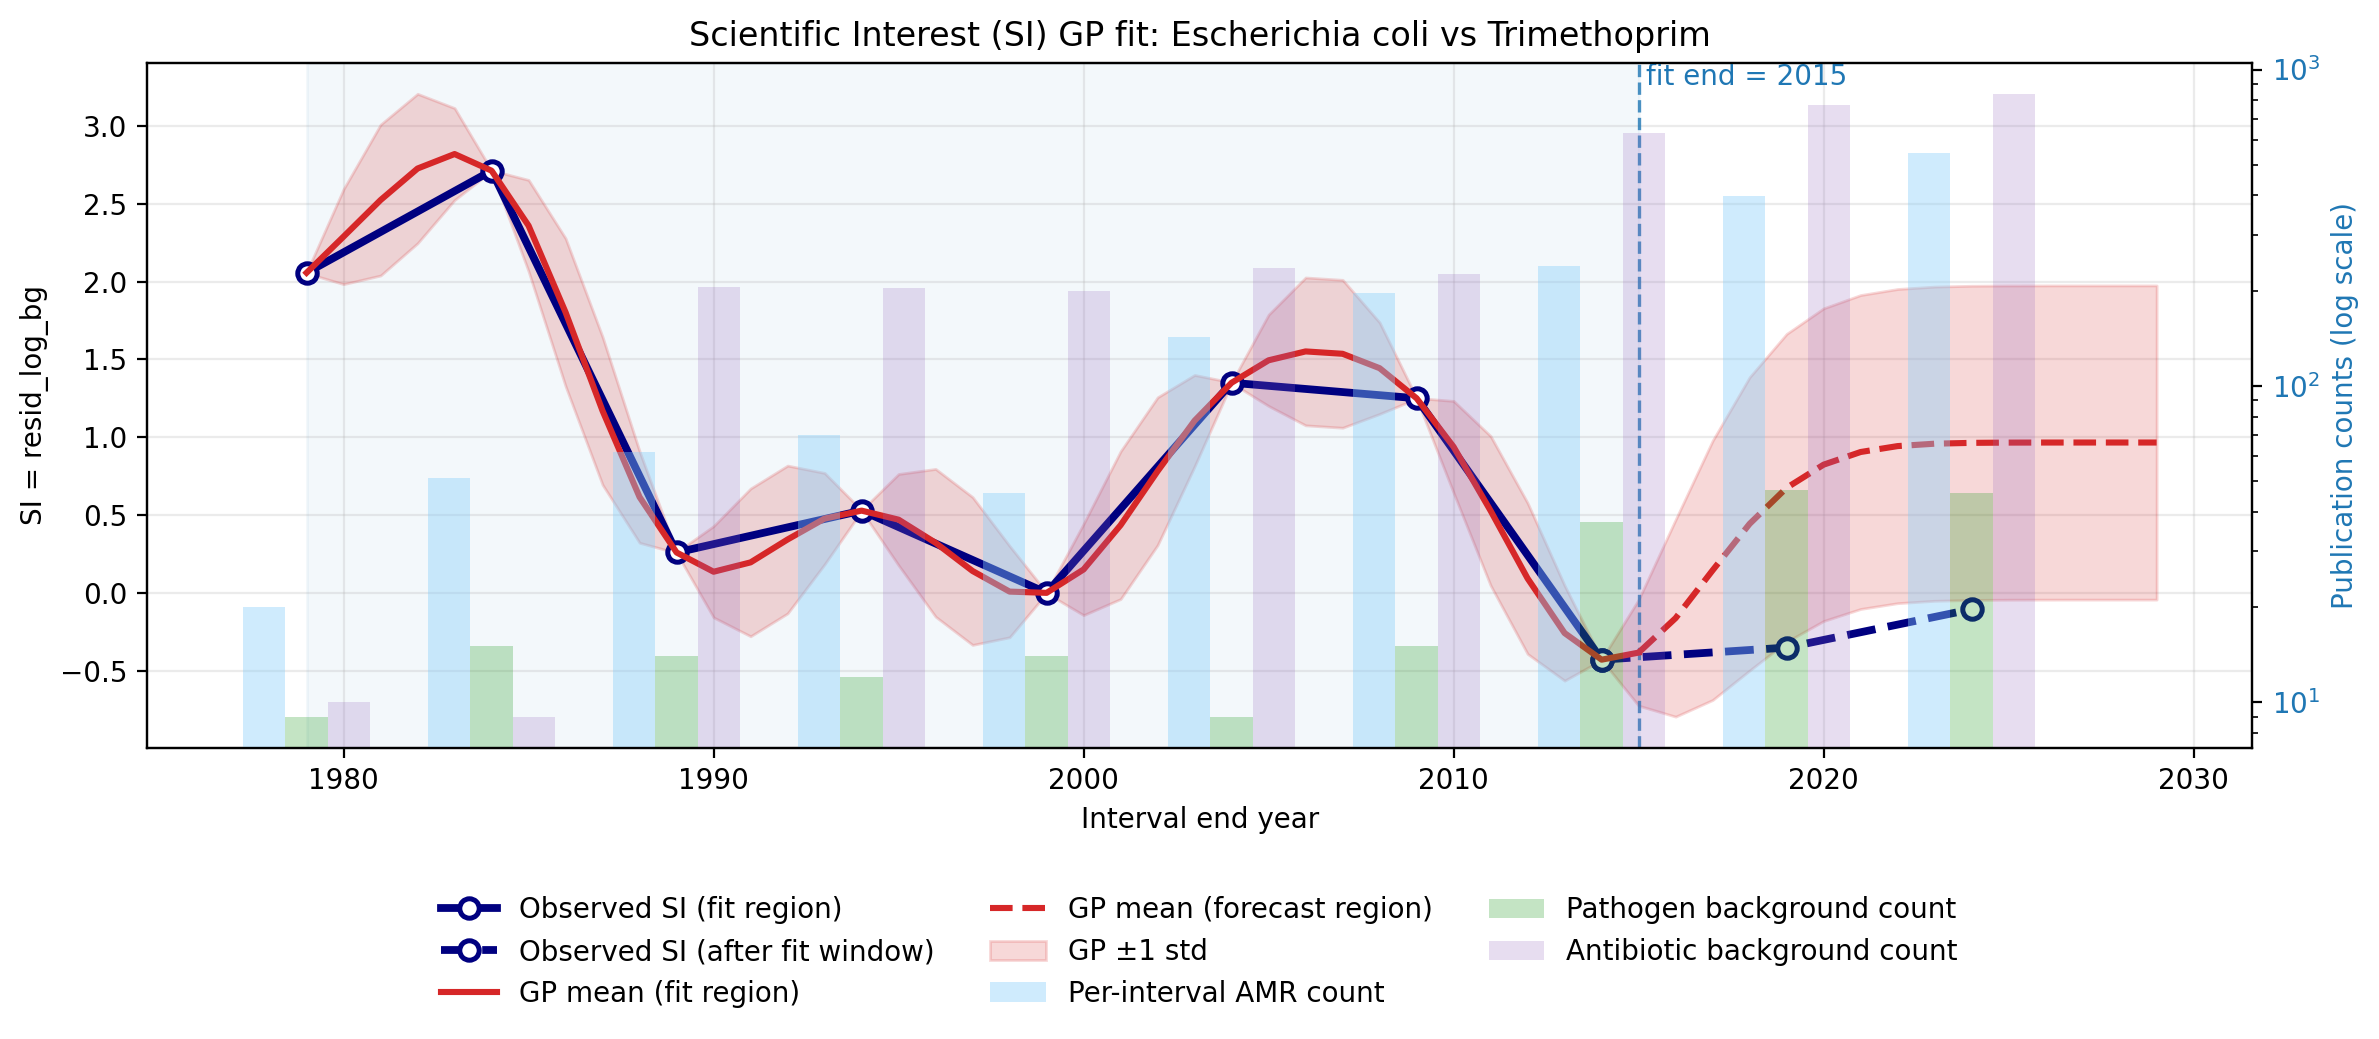

,year,observed_SI,predicted_SI,predicted_std,lower_1std,upper_1std,prediction_error,abs_error,within_1std
0,2019,-0.351371,0.674766,0.988802,-0.314036,1.663568,-1.026137,1.026137,False
1,2024,-0.105410,0.963654,1.009105,-0.045451,1.972760,-1.069065,1.069065,False


Optimized kernel: 1.01**2 * RBF(length_scale=2.77) + WhiteKernel(noise_level=2.58e-06)
Latest observed interval end year: 2024


In [81]:
result = plot_si_prediction(
    si_df=si_df,
    pathogen="Escherichia coli",
    antibiotic="Trimethoprim",
    fit_start_year=1970,
    fit_end_year=2015,
    num_additional_years=5,
)

display(result["comparison_df"])
print("Optimized kernel:", result["gp"].kernel_)
print("Latest observed interval end year:", result["latest_available_year"])

In [82]:
COMPUTE_ALL_FORECASTS = False
if COMPUTE_ALL_FORECASTS:
    forecast_df = forecast_si_for_all_pairs(
        si_df,
        fit_start_year=1970,
        fit_end_year=2015,
        num_additional_years=5,
    )

In [83]:
forecast_path = "si_pair_forecasts_fit_1970_2015_target_2031.parquet"

forecast_df = pd.read_parquet(forecast_path)

top_si_df = (
    forecast_df.loc[forecast_df["status"] == "ok"]
    .sort_values(["predicted_SI_mean", "predicted_SI_std"], ascending=[False, True])
    .reset_index(drop=True)
)

display(
    top_si_df[
        [
            "pathogen",
            "antibiotic",
            "forecast_year",
            "predicted_SI_mean",
            "predicted_SI_std",
            "predicted_SI_lower_1std",
            "predicted_SI_upper_1std",
            "amr_pair_total_count",
            "n_train_intervals",
        ]
    ].head(30)
)

FileNotFoundError: [Errno 2] No such file or directory: 'si_pair_forecasts_fit_1970_2015_target_2031.parquet'